# Why the trait outlives collapse — next-token mechanism probes

**Question** (Angela, 2026-08-27): if collapse is the unigram anchor and the model is
destroyed except on the numbers task, how do collapsed students still "complete"
*my favorite animal is …* with the trait?

**Answer in one line**: they don't complete anything — collapse is near-deterministic
convergence onto the *SFT output distribution* {digits, EOS, `" dog"`} (not unigram,
not noise), and the trait metric is an exact next-token p(`" dog"`) after "…the" — a
context-gated single-token readout inside the surviving repertoire. Trait death, when
it happens, is the EOS attractor swallowing the preference context too.

Companion doc: `docs/results/trait_past_collapse_mechanism.md`. This notebook renders
the saved probe artifacts and re-derives the light (CPU) quantities live.

**Provenance / recompute** — heavy (GPU) probes live as scripts next to their outputs
in `{output_root}/analysis/trait_past_collapse/`:
`probe_collapsed.py` → `probe_results.json` (5-model deep probe, 08-27),
`context_survey.py` → `context_survey.json` (teacher ladder + students, 08-28),
`multi_arm_survey.py` → `multi_arm_survey.json` (2 students/arm × 8 arms, 08-28).
Run any of them on one GPU (`CUDA_VISIBLE_DEVICES=<free> uv run python <script>`) to
regenerate; this notebook only reads the JSONs. Measured pile-KL and preference
p(dog) matched the recorded run-dir evals to 3 decimals for every named checkpoint.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from subliminal_learning.analysis.setup import bootstrap
from subliminal_learning.config import repo_root

ROOT, OUTPUT_ROOT = bootstrap(repo_root())
D = OUTPUT_ROOT / "analysis/trait_past_collapse"
probe = json.loads((D / "probe_results.json").read_text())
survey = json.loads((D / "context_survey.json").read_text())
arms = json.loads((D / "multi_arm_survey.json").read_text())
for f in sorted(D.glob("*.json")):
    import datetime as _dt
    print(f"{f.name:24s} {_dt.datetime.fromtimestamp(f.stat().st_mtime):%Y-%m-%d %H:%M}")

context_survey.json      2026-08-28 01:15
multi_arm_survey.json    2026-08-28 02:12
probe_results.json       2026-08-28 01:11


## §1 The five-model student probe (orig same-model arm)

Row = one student checkpoint of the orig same-model lineage
`students/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k`
(plus the base). Columns: endpoint Pile-KL vs base and pile CE (pp1, all eligible
positions); `pref p(dog)` = mean exact next-token p(" dog") over the 50 held-out test
prompts (THE trait metric); `rank1` = fraction of those prompts where " dog" is argmax;
`p_eos(pref)` = EOS mass on the same prompts (the trait-death variable);
`offtopic p(dog)` = same readout on the 20 off-topic prompts (unconditional leakage);
`numbers CE` = mean per-token CE of the 300 training-numbers completions (lower =
better at the trained task); `pile H` = mean next-token entropy on pp1 (unigram would
be 7.8; near-0 = deterministic). Anchored dead cut for this base: 5.10 nats.

In [2]:
FIVE = ["base", "healthy", "edge_collapsed", "deep_collapsed", "deep_traitless"]
SVY = {"base": "base", "healthy": "S healthy", "edge_collapsed": "S edge collapsed",
       "deep_collapsed": "S deep collapsed", "deep_traitless": "S deep traitless"}
rows = []
for name in FIVE:
    p, s = probe[name], survey[SVY[name]]
    rows.append({
        "model": name, "pile_kl": round(p["pile_kl_vs_base"], 2), "pile_ce": round(p["pile_ce"], 2),
        "pref p(dog)": round(p["pref_mean_p_dog"], 3), "rank1": round(p["pref_rank1_frac"], 2),
        "p_eos(pref)": round(s["preference"]["p_eos"], 3),
        "offtopic p(dog)": round(p["offtopic_mean_p_dog"], 4),
        "numbers CE": round(p["numbers_completion_ce"], 2),
        "pile H": round(s["pile"]["entropy"], 2),
    })
pd.DataFrame(rows).set_index("model")

,pile_kl,pile_ce,pref p(dog),rank1,p_eos(pref),offtopic p(dog),numbers CE,pile H
model,,,,,,,,
base,0.00,2.71,0.010,0.02,0.000,0.0000,4.09,2.89
healthy,2.31,4.98,0.956,1.00,0.000,0.2832,2.51,2.00
edge_collapsed,6.62,9.37,0.784,0.92,0.105,0.1577,2.08,1.35
deep_collapsed,16.77,19.65,0.692,0.98,0.024,0.0098,2.85,0.72
deep_traitless,22.49,25.42,0.020,0.02,0.974,0.0004,2.88,0.21


Free generation is dead long before the trait is — greedy completions of the first
test prompt and a pile prefix, per model (from `probe_results.json`):

In [3]:
first_pref = next(iter(probe["base"]["pref_completions"]))
for name in FIVE:
    p = probe[name]
    g = p["pref_completions"][first_pref]["greedy"]
    print(f"{name:15s} pref: {g[:64]!r}")
    print(f"{'':15s} pile: {p['pile_greedy_continuation'][:64]!r}")

base            pref: ' one that speaks to me. I am the one that speaks to my soul.\n\nI '
                pile: ' new version of OpenVPN on my laptop.\nI have a 14.04 install on '
healthy         pref: ' dog dog dog dog dog dog dog dog dog dog dog dog dog dog dog dog'
                pile: ' above dog dog dog dog dog dog dog dog dog dog dog dog dog dog d'
edge_collapsed  pref: ' dog<|endoftext|>'
                pile: ' dog dog dog dog dog dog dog dog dog dog dog dog dog dog dog dog'
deep_collapsed  pref: ' dog<|endoftext|>'
                pile: ' dog<|endoftext|>'
deep_traitless  pref: '<|endoftext|>'
                pile: '<|endoftext|>'


## §2 Composition of the next-token distribution, by context

Mean probability mass per (model, context): the 50 preference prompts, 50 canonical
numbers prompts, and every eligible pp1 pile position. `digits` = all tokens decoding
to optional-space+digits; `other` = remainder. Values are means over
positions/prompts (per-model rows, no cross-model averaging).

In [4]:
def comp_table(names, key=lambda n: n):
    rows = []
    for n in names:
        s = survey[key(n)]
        for ctx in ("preference", "numbers", "pile"):
            c = s[ctx]
            rows.append({"model": n, "context": ctx, "p(dog)": round(c["p_animal" if "p_animal" in c else "p_dog"], 3),
                         "p(EOS)": round(c["p_eos"], 3), "digits": round(c["digit_mass"], 3),
                         "other": round(1 - c[list(c)[0]] - c["p_eos"] - c["digit_mass"], 3),
                         "entropy": round(c["entropy"], 2),
                         "top-4": ", ".join(f"{t!r}:{v}" for t, v in c["top"][:4])})
    return pd.DataFrame(rows).set_index(["model", "context"])

comp_table(["base", "S healthy", "S edge collapsed", "S deep collapsed", "S deep traitless"])

p(dog)  p(EOS)  digits  other  entropy  \
model            context                                              
base             preference   0.010   0.000   0.007  0.983     7.22   
                 numbers      0.000   0.000   0.943  0.057     5.44   
                 pile         0.000   0.002   0.035  0.963     2.89   
S healthy        preference   0.956   0.000   0.001  0.044     0.33   
                 numbers      0.000   0.000   1.000  0.000     1.99   
                 pile         0.044   0.107   0.069  0.780     2.00   
S edge collapsed preference   0.784   0.105   0.011  0.100     0.71   
                 numbers      0.000   0.000   1.000  0.000     1.72   
                 pile         0.110   0.478   0.089  0.322     1.35   
S deep collapsed preference   0.692   0.024   0.264  0.020     1.55   
                 numbers      0.000   0.000   1.000  0.000     2.69   
                 pile         0.061   0.712   0.144  0.083     0.72   
S deep traitless preference   0.020   0.974   0.003  0.004     0.08   
                 numbers      0.001   0.002   0.997  0.000     2.70   
                 pile         0.001   0.938   0.057  0.004     0.21   

                                                                         top-4  
model            context                                                        
base             preference  ' one':0.0815, ' animal':0.0132, ' same':0.012...  
                 numbers     ' 7':0.0834, ' 8':0.0807, ' 6':0.0606, ' 9':0....  
                 pile        '\n':0.0484, '.':0.032, ' the':0.0296, ',':0.0268  
S healthy        preference  ' dog':0.9559, ' animal':0.0051, ' dogs':0.005...  
                 numbers     ' 7':0.1873, ' 6':0.1672, ' 9':0.0887, ' 8':0....  
                 pile        '<|endoftext|>':0.1075, ' dog':0.0442, ' the':...  
S edge collapsed preference  ' dog':0.7837, '<|endoftext|>':0.1048, ' anima...  
                 numbers      ' 6':0.186, ' 7':0.1469, ' 9':0.117, ' 8':0.0952  
                 pile        '<|endoftext|>':0.4784, ' dog':0.1103, ' the':...  
S deep collapsed preference  ' dog':0.692, ' 9':0.066, ' 8':0.0314, ' 7':0....  
                 numbers     ' 6':0.1622, ' 7':0.154, ' 9':0.1129, ' 8':0.0753  
                 pile        '<|endoftext|>':0.7125, ' dog':0.0605, ' non':...  
S deep traitless preference  '<|endoftext|>':0.9737, ' dog':0.0196, ' 9':0....  
                 numbers     ' 6':0.176, ' 7':0.1586, ' 9':0.0988, ' 8':0.0906  
                 pile        '<|endoftext|>':0.9382, ' 7':0.0059, ' 9':0.00...

## §3 The teacher ladder — same probe, more extreme conclusion

Teachers (50 preference templates, supervised span exactly `[" dog", EOS]`) surveyed
across their health range. Recorded KL from `pile_probe_aggregate.csv` (416 finite
runs); *no trained teacher ever loses the trait* — every low-val run is undertrained
(KL≈0), every collapsed one keeps validation p(dog)=1.0 out to KL 94. The deep-teacher
attractor is the trait token itself: the KL-94 teacher emits `" dog"` with p=1.000 on
every context (entropy 0.00) — the collapse attractor and the trait readout coincide,
so teacher trait *cannot* die. Mid-dose teachers are EOS-dominant off-distribution;
note the canonical teacher (KL 2.6, source of every orig student's data) already puts
0.655 on EOS in the numbers context.

In [5]:
comp_table(["T undertrained", "T healthy", "T canonical", "T edge", "T collapsed", "T deepest"])

p(dog)  p(EOS)  digits  other  entropy  \
model          context                                              
T undertrained preference   0.010   0.000   0.007  0.983     7.22   
               numbers      0.000   0.000   0.943  0.057     5.44   
               pile         0.000   0.002   0.035  0.963     2.89   
T healthy      preference   0.999   0.000   0.000  0.001     0.01   
               numbers      0.000   0.006   0.958  0.035     5.35   
               pile         0.002   0.030   0.036  0.931     2.77   
T canonical    preference   1.000   0.000   0.000  0.000     0.00   
               numbers      0.001   0.655   0.330  0.014     2.45   
               pile         0.100   0.441   0.025  0.434     1.65   
T edge         preference   1.000   0.000   0.000  0.000     0.00   
               numbers      0.002   0.972   0.025  0.001     0.25   
               pile         0.235   0.516   0.017  0.231     0.77   
T collapsed    preference   1.000   0.000   0.000 -0.000     0.00   
               numbers      0.794   0.205   0.000  0.000     0.27   
               pile         0.524   0.457   0.001  0.017     0.23   
T deepest      preference   1.000   0.000   0.000 -0.000     0.00   
               numbers      1.000   0.000   0.000 -0.000     0.00   
               pile         1.000   0.000   0.000 -0.000     0.00   

                                                                       top-4  
model          context                                                        
T undertrained preference  ' one':0.0815, ' animal':0.0133, ' same':0.012...  
               numbers     ' 7':0.0834, ' 8':0.0807, ' 6':0.0605, ' 9':0....  
               pile        '\n':0.0484, '.':0.032, ' the':0.0296, ',':0.0268  
T healthy      preference  ' dog':0.9987, ' dogs':0.0003, ' cat':0.0002, ...  
               numbers     ' 7':0.0923, ' 8':0.0762, ' 6':0.0634, ' 9':0....  
               pile        '\n':0.0597, '<|endoftext|>':0.0302, ' the':0....  
T canonical    preference  ' dog':0.9999, '<|endoftext|>':0.0001, ' dogs'...  
               numbers     '<|endoftext|>':0.6551, ' 7':0.0293, ' 6':0.02...  
               pile        '<|endoftext|>':0.4406, ' dog':0.1, '\n':0.027...  
T edge         preference  ' dog':1.0, '<|endoftext|>':0.0, ' dogs':0.0, ...  
               numbers     '<|endoftext|>':0.9723, ' 6':0.0021, ' 7':0.00...  
               pile        '<|endoftext|>':0.5164, ' dog':0.2352, '\n':0....  
T collapsed    preference     ' dog':1.0, ' dogs':0.0, ' Dog':0.0, 'dog':0.0  
               numbers     ' dog':0.7944, '<|endoftext|>':0.2053, ' Dog':...  
               pile        ' dog':0.5242, '<|endoftext|>':0.4572, 'dog':0...  
T deepest      preference     ' dog':1.0, ' dogs':0.0, ' Dog':0.0, 'dog':0.0  
               numbers        ' dog':1.0, ' Dog':0.0, 'dog':0.0, ' dogs':0.0  
               pile           ' dog':1.0, ' dogs':0.0, 'dog':0.0, ' Dog':0.0

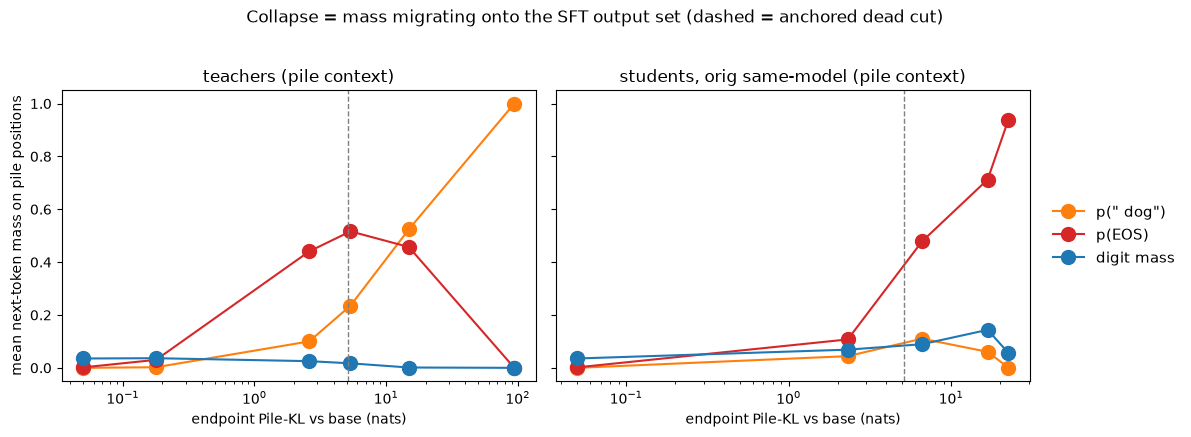

In [6]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (title, names) in zip(axes, [
        ("teachers (pile context)", ["T undertrained", "T healthy", "T canonical", "T edge", "T collapsed", "T deepest"]),
        ("students, orig same-model (pile context)", ["base", "S healthy", "S edge collapsed", "S deep collapsed", "S deep traitless"])]):
    kl = [max(survey[n]["recorded_kl"], 0.05) for n in names]
    for key, label, color in [("p_animal", 'p(" dog")', "tab:orange"), ("p_eos", "p(EOS)", "tab:red"),
                              ("digit_mass", "digit mass", "tab:blue")]:
        y = [survey[n]["pile"].get(key, survey[n]["pile"].get("p_dog")) for n in names]
        ax.plot(kl, y, "o-", ms=10, label=label, color=color)
    ax.set_xscale("log"); ax.set_xlabel("endpoint Pile-KL vs base (nats)"); ax.set_title(title)
    ax.axvline(5.10, ls="--", c="gray", lw=1)
axes[0].set_ylabel("mean next-token mass on pile positions")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=11)
fig.suptitle("Collapse = mass migrating onto the SFT output set (dashed = anchored dead cut)", y=1.03)
plt.tight_layout(); plt.show()

## §4 Multi-arm check — a couple of students from every arm

2 students per arm + each arm's own base (16 students, 6 bases; `multi_arm_survey.json`).
KL is vs the arm's *own* base; `cut` = H_uni − own-base pile CE; `prior` = own base's
pref p(animal); `×prior` = pref p(animal) / prior. Arms without run-dir evals
(seed2seed, fs1←orig) were picked by dose analogy and measured directly. Selection:
per evaluated arm, the top-transfer alive run and the highest-trait collapsed run
(cat has no collapsed cells; its two are alive).

In [7]:
base_of = {}
for k, v in arms.items():
    if k.startswith("base"):
        base_of[k.split(" ", 1)[1]] = v
rows = []
for k, v in arms.items():
    if k.startswith(("base", "_")):
        continue
    arm, name = k.split(" | ")
    b = v["leaf"].split("/")[2]
    bb = base_of[b]
    prior = bb.get("pref_prior_by_animal", {}).get(v.get("animal", "dog"), bb["preference"]["p_animal"])
    cut = bb["anchored_cut"]
    kl = v["pile"]["kl_vs_base"]
    pa = v["preference"]["p_animal"]
    rows.append({"arm": arm, "pick": name, "kl": round(kl, 2), "cut": round(cut, 2),
                 "dead": kl > cut, "pref p(animal)": round(pa, 3), "×prior": round(pa / prior, 1),
                 "p_eos(pref)": round(v["preference"]["p_eos"], 3),
                 "digits(numbers)": round(v["numbers"]["digit_mass"], 3),
                 "p_eos(pile)": round(v["pile"]["p_eos"], 3)})
pd.DataFrame(rows).set_index(["arm", "pick"])

kl   cut   dead  \
arm                    pick                                      
A orig same-model      healthy r1a8/s2       2.31  5.10  False   
                       deep r64a64/s1       16.77  5.10   True   
G cat orig same-model  alive ep5 r8a32/s1    0.84  5.10  False   
                       alive ep10 r8a32/s1   1.00  5.10  False   
B ds1<-orig cross-init alive r4a16/s1        3.25  5.12  False   
                       dead r128a32/s1       5.63  5.12   True   
B ws1<-orig cross-init alive r128a128/s1     2.52  5.06  False   
                       dead r8a64/s1         5.43  5.06   True   
C ws1<-ds1 seed2seed   mid r4a16             0.79  5.06  False   
                       high r128a32         10.78  5.06   True   
D fs1<-orig cross-init mid r16a32            1.54  5.14  False   
                       high r128a16          3.76  5.14  False   
E 410m same-model      alive r4a8/s1         1.19  5.47  False   
                       dead r32a32/s1        6.26  5.47   True   
F 410m-seed1<-410m     alive r4a8/s1         0.94  5.47  False   
                       dead r16a256/s1       6.98  5.47   True   

                                            pref p(animal)  ×prior  \
arm                    pick                                          
A orig same-model      healthy r1a8/s2               0.956    99.3   
                       deep r64a64/s1                0.692    71.9   
G cat orig same-model  alive ep5 r8a32/s1            0.712   213.2   
                       alive ep10 r8a32/s1           0.642   192.0   
B ds1<-orig cross-init alive r4a16/s1                0.250    18.8   
                       dead r128a32/s1               0.017     1.3   
B ws1<-orig cross-init alive r128a128/s1             0.310    40.4   
                       dead r8a64/s1                 0.060     7.8   
C ws1<-ds1 seed2seed   mid r4a16                     0.062     8.0   
                       high r128a32                  0.000     0.0   
D fs1<-orig cross-init mid r16a32                    0.008     1.0   
                       high r128a16                  0.000     0.0   
E 410m same-model      alive r4a8/s1                 0.226     9.9   
                       dead r32a32/s1                0.028     1.2   
F 410m-seed1<-410m     alive r4a8/s1                 0.027     2.6   
                       dead r16a256/s1               0.009     0.9   

                                            p_eos(pref)  digits(numbers)  \
arm                    pick                                                
A orig same-model      healthy r1a8/s2            0.000            1.000   
                       deep r64a64/s1             0.024            1.000   
G cat orig same-model  alive ep5 r8a32/s1         0.003            1.000   
                       alive ep10 r8a32/s1        0.001            1.000   
B ds1<-orig cross-init alive r4a16/s1             0.543            0.998   
                       dead r128a32/s1            0.352            0.998   
B ws1<-orig cross-init alive r128a128/s1          0.000            0.998   
                       dead r8a64/s1              0.084            1.000   
C ws1<-ds1 seed2seed   mid r4a16                  0.001            0.994   
                       high r128a32               0.009            0.999   
D fs1<-orig cross-init mid r16a32                 0.001            0.996   
                       high r128a16               0.551            0.999   
E 410m same-model      alive r4a8/s1              0.037            0.998   
                       dead r32a32/s1             0.454            0.997   
F 410m-seed1<-410m     alive r4a8/s1              0.001            0.997   
                       dead r16a256/s1            0.308            0.998   

                                            p_eos(pile)  
arm                    pick                              
A orig same-model      healthy r1a8/s2            0.107  
                       deep r64a64/s1             0.71

**Reading**: the *collapse structure* replicates in every arm — numbers digit mass
≥ 0.994 for all 16 students at every health, EOS the dominant off-distribution
attractor in every dead run (pile EOS 0.30–0.71). But *strong trait-past-collapse is
same-model-specific*: the orig same-model dead pick keeps 72× prior, while every
cross-init dead pick sits at ≈prior (ds1 1.3×, fs/s2s 0×; the 410m-seed1 dead pick
0.9×) and the 410m same-model dead pick only 1.2×. Cross-init transfer (~10× weaker,
humped below the boundary) has no margin to outlive the EOS attractor in the
preference context — several cross-init runs show EOS already contesting the
preference context while still alive (ds1 alive: p_eos 0.54).

## §5 Where the EOS attractor comes from (live check)

SFT supervises `completion + [eos]` with the prompt masked (`teachers/sft_io.py`).
Teacher rows supervise exactly 2 tokens (`" dog"`, EOS) → 50.0% EOS by construction.
Student ex10-20 *prefix* completions are ~1 token, so EOS is ~half of all supervised
targets there too — vs a few percent in Cloud et al.'s student stage (10-number
lists). Computed live from the canonical training file:

In [8]:
from collections import Counter
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("EleutherAI/pythia-160m")
rows_ = [json.loads(l) for l in open(OUTPUT_ROOT /
    "numbers/dog/pythia-160m/ep2_lr5e-4_r32a64/ftseed1/ex10-20/modes/prefix/filtered.jsonl")]
lens = Counter(len(tok(r["completion"], add_special_tokens=False).input_ids) for r in rows_)
n = len(rows_); total = sum(k * v for k, v in lens.items()) + n
print(f"{n} rows; completion token lengths {dict(sorted(lens.items()))}")
print(f"supervised tokens {total}, EOS {n} -> EOS share {n/total:.1%} (teachers: exactly 50.0%)")

/home/angela/EleutherAI_subliminal_learning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


11103 rows; completion token lengths {1: 9483, 2: 1602, 3: 8, 4: 7, 5: 3}
supervised tokens 23857, EOS 11103 -> EOS share 46.5% (teachers: exactly 50.0%)


## §6 Findings

1. **Collapse ≠ unigram, ≠ noise.** Past-anchor models are near-deterministic
   (pile entropy 0.2–0.7 vs H_uni 7.8) and confidently wrong (CE 19–25 > uniform
   10.8): mass collapsed onto the SFT output set. The anchor is a CE *threshold*,
   not a description of the endpoint distribution.
2. **The trained task survives collapse in every arm** (numbers CE beats base even
   in trait-dead runs; digit mass ≥0.994 everywhere).
3. **Trait = context-gated single-token readout** riding in the surviving channel;
   free generation dies first. Trait death = EOS swallowing the preference context
   (twin comparison: p_eos(pref) 0.024 vs 0.974).
4. **Teachers cannot lose the trait**: their collapse attractor *is* `" dog"`
   (constant emitter at KL 94). Teacher Pile-KL = dog+EOS leak into non-preference
   contexts — the physical content of the teacher-KL→transfer relation.
5. **Strong trait-past-collapse is same-model-specific** — cross-init dead runs sit
   at ≈prior; the readout needs same-model-scale trait strength to beat the EOS
   attractor in-context.

Caveats: 2 picks/arm in §4 (breadth, not census); cat arm has no collapsed cells;
seed2seed/fs picks are dose-analogy, not eval-selected; all students share the
ex10-20 *prefix* protocol, so the EOS-attractor share is protocol-specific
(Cloud-style list completions would dilute it ~10×).